<a href="https://colab.research.google.com/github/Qdowling/MLS_python_project_QDowling/blob/main/Python_project_EK_QD_AB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
from scipy.linalg import expm
from scipy.optimize import minimize_scalar
import matplotlib.pyplot as plt

# ======================================================================
# 1. INPUT DATA
# ======================================================================
msa = """>Bos
AGCTCAAGCTCAAGCTCAAGCTCAAGCTCA
>Ovis
CGTTACCGTTACCGTTACCGTTACCGTTAC
>Felis
CGCTACCGCTACCGCTACCGCTACCGCTAC
>Homo
AGATCAAGATCAAGATCAAGATCAAGATCA
>Mus
CGCTATCGCTATCGCTATCGCTATCGCTAT"""

# 2. Edges: Each edge is (parent, child). Internal nodes are ints, leaves are names.
edges = [(9, "Bos"), (9, "Ovis"), (8, 9), (8, "Felis"),
         (7, "Homo"), (7, "Mus"), (6, 7), (6, 8)]

# The i-th length belongs to the i-th edge.
lengths = [0.1, 0.4, 0.01, 0.04, 0.2, 0.08, 0.12, 0.14]


# ======================================================================
# 2. ALIGNMENT CLASS (stores names, sequences, and the one-hot vectors)
# ======================================================================
class Alignment:
    STATES = "ACGT"                                   # order of the 4 vector entries
    STATE_INDEX = {s: i for i, s in enumerate(STATES)}

    def __init__(self, msa_string):
        # --- your original parsing code, unchanged in logic ---
        list_msa = msa_string.split("\n")
        self.seqDict = {}
        index = 0
        while index < len(list_msa):
            elem = list_msa[index]
            if elem[0] == ">":                        # a name line
                name = elem.lstrip(">")
                seq = list_msa[index + 1]             # sequence is on the next line
                self.seqDict[name] = seq
            index += 1

        self.names = list(self.seqDict.keys())
        self.n_sites = len(self.seqDict[self.names[0]])

        # Every sequence in an alignment must have the same length.
        assert all(len(s) == self.n_sites for s in self.seqDict.values()), \
            "Sequences have different lengths, so this is not an alignment"

        # Build the one-hot vectors ONCE for all leaves and all sites.
        # leaf_vectors[name] has shape (n_sites, 4), and row i is the state
        # vector u of that leaf at site i, e.g. A -> [1, 0, 0, 0].
        self.leaf_vectors = {name: self._to_vectors(seq)
                             for name, seq in self.seqDict.items()}

    def _to_vectors(self, seq):
        U = np.zeros((len(seq), 4))
        for i, base in enumerate(seq.upper()):
            if base in self.STATE_INDEX:
                U[i, self.STATE_INDEX[base]] = 1.0
            else:
                U[i, :] = 1.0                         # gap or N: any state possible
        return U

In [ ]:
# ======================================================================
# 3. TREE CLASS (stores the topology and branch lengths)
# ======================================================================
class Tree:
    def __init__(self, edges, lengths):
        assert len(edges) == len(lengths), "Need one length per edge"

        # children[parent] = list of (child, branch_length)
        self.children = {}
        # branch_length[child] = length of the branch leading INTO that child.
        # Every node except the root has exactly one parent, so this is unambiguous.
        self.branch_length = {}

        all_children = set()
        for (parent, child), t in zip(edges, lengths):
            self.children.setdefault(parent, []).append((child, t))
            self.branch_length[child] = t
            all_children.add(child)

        # The root is the only parent that is never a child.
        self.root = (set(self.children) - all_children).pop()

        # Internal nodes ordered so that children come BEFORE their parents.
        # This is the order in which pruning must be performed.
        self.postorder = self._postorder(self.root)

    def _postorder(self, node):
        if node not in self.children:                 # leaf: nothing to compute
            return []
        order = []
        for child, _ in self.children[node]:
            order += self._postorder(child)
        order.append(node)                            # node comes after its children
        return order


In [ ]:
# ======================================================================
# 4. MODEL: Jukes-Cantor Q matrix
# ======================================================================
def make_Q(mu):
    """Off-diagonal entries = mu, diagonal = -3*mu, so each row sums to 0."""
    Q = np.full((4, 4), mu)
    np.fill_diagonal(Q, -3.0 * mu)
    return Q

PI = np.full(4, 0.25)                                 # equilibrium frequencies


# ======================================================================
# 5. LOG-LIKELIHOOD FOR A FIXED mu  (task 2a)
# ======================================================================
def log_likelihood(tree, aln, mu, return_sites=False):
    Q = make_Q(mu)

    # Transition matrix e^(Q*t) for each branch, computed ONCE per mu
    # (not once per site). P[child][i, j] = probability that the parent is in
    # state i and the child is in state j after time t.
    P = {child: expm(Q * t) for child, t in tree.branch_length.items()}

    site_logliks = np.zeros(aln.n_sites)

    # ---- loop over alignment columns (sites) ----
    for site in range(aln.n_sites):

        # v[node] is the 4-element likelihood vector at that node.
        # For leaves it is the one-hot vector u of the observed nucleotide.
        v = {leaf: aln.leaf_vectors[leaf][site] for leaf in aln.names}

        # Visit internal nodes from the tips toward the root (Felsenstein pruning).
        for node in tree.postorder:
            v_node = np.ones(4)                       # neutral element of the product
            for child, t in tree.children[node]:
                # Propagate the child's vector up its branch: e^(Q t) x v_child.
                # Entry i = P(subtree data below child | node has state i).
                propagated = P[child] @ v[child]
                # Merge siblings with the element-wise (Hadamard) product.
                v_node = v_node * propagated
            v[node] = v_node

        # At the root, weight by equilibrium frequencies: L(D_i | T) = pi . v_root
        site_lik = PI @ v[tree.root]
        site_logliks[site] = np.log(site_lik)

    total = site_logliks.sum()                        # sum of ln L over all sites
    return (total, site_logliks) if return_sites else total


In [ ]:
# ======================================================================
# 6. RUN IT
# ======================================================================
aln = Alignment(msa)
tree = Tree(edges, lengths)

print("Number of sequences:", len(aln.seqDict))
print("Number of sites    :", aln.n_sites)
print("Root node          :", tree.root)
print("Postorder (internal):", tree.postorder)

Number of sequences: 5
Number of sites    : 30
Root node          : 6
Postorder (internal): [7, 9, 8, 6]


In [ ]:
# Sanity check: rows of P(t) must sum to 1 (valid probabilities).
assert np.allclose(expm(make_Q(0.3) * 0.1).sum(axis=1), 1.0)

# --- 2a: fixed mu = 0.3 ---
lnL, per_site = log_likelihood(tree, aln, mu=0.3, return_sites=True)
print(f"\nlnL at mu = 0.3: {lnL:.4f}")
print("First 5 per-site ln-likelihoods:", np.round(per_site[:5], 4))



lnL at mu = 0.3: -195.0269
First 5 per-site ln-likelihoods: [-8.4868 -2.3259 -7.0595 -2.3259 -8.4868]


In [ ]:
# --- 2b: range of mu values ---
mu_values = np.linspace(0.02, 2.0, 100)
lnL_values = [log_likelihood(tree, aln, mu) for mu in mu_values]

# Coarse estimate from the grid ...
mu_hat_grid = mu_values[np.argmax(lnL_values)]
# ... refined with a 1-D optimiser (maximise lnL = minimise -lnL).
res = minimize_scalar(lambda m: -log_likelihood(tree, aln, m),
                      bounds=(0.001, 5.0), method="bounded")
mu_hat = res.x
print(f"mu-hat (grid)     : {mu_hat_grid:.3f}")
print(f"mu-hat (optimised): {mu_hat:.4f}   lnL = {-res.fun:.4f}")


mu-hat (grid)     : 0.700
mu-hat (optimised): 0.6909   lnL = -185.4023


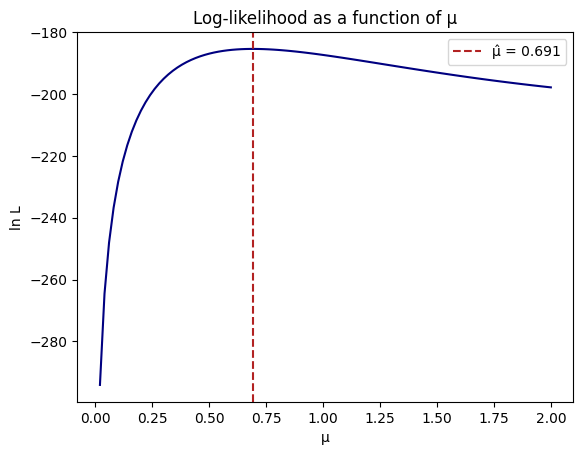

In [ ]:
# --- plot like the slide ---
plt.plot(mu_values, lnL_values, color="navy")
plt.axvline(mu_hat, color="firebrick", linestyle="--", label=f"µ̂ = {mu_hat:.3f}")
plt.xlabel("µ")
plt.ylabel("ln L")
plt.title("Log-likelihood as a function of µ")
plt.legend()
plt.show()

In [ ]:
# Run with new data (EHD3)

# Load in the msa
msa = """Equus_przewalskii ATTGTAACTGGACGAGAACTTGGCCCCCGCCGGAGGAAGGACCCCGAGGTCTTCCAGACAGTGAGCGAGGGGCTCAAGAAACTCTATAAGAGCAAGCTGCTACCCCTGGAAGAGCATTACCGCTTCCACGAGTTTCACTCGCCTGCCCTGGAGGATGCCGATTTCGACAACAAGCCCATGGTCCTGCTGGTGGGCCAATAC
Rattus_norvegicus ATGTTCAGCTGGCTGGGTAACGATGATCGCCGCAAGAAGGACCCTGAGGTCTTCCAGACCGTGAGCGAGGGGCTCAAGAAACTCTACAAGACCAAGCTGCTGCCTCTGGAAGAGTATTACCGCTTCCACGAGTTCCACTCGCCGGCCTTGGAGGATGCTGATTTCGACAACAAGCCCATGGTCCTGTTGGTGGGCCAATAC
Ailuropoda_melanoleuca ATGTTCAGCTGGCTGGGTTCCGACGACCGCCGGCGGAAGGACCCCGAGGTCTTCCAGACGGTGAGCGAGGGGCTCAAGAAACTCTACAAGACCAAGCTGCTGCCCCTGGAAGAGCATTACCGCTTCCACGAGTTTCACTCGCCCGCCCTGGAGGATGCCGATTTCGACAACAAGCCCATGGTCCTGCTGGTGGGCCAGTAC
Mustela_putorius TGGGACAAATAGCCGGCAACCCAGCCGGCAAATAATTACACATCGTCTGCGTTACTCACCCACATACGGATAAATCTCCTTTTCGATAATGAGCGCCGGTTCCTTTACCTAAAACCATTGGGTTTATAGGCTCTCTTGTGTCGCGATATACAATTTCCACGTCAACGCAACGGACCGATGGTCCTGCTGGTGGGCCAGTAC
Odobenus_rosmarus_divergens ATGTTCAGCTGGCTGGGTTCCGATGACCGCCGGCGGAAGGACCCCGAGGTCTTCCAGACCGTGAGCGAGGGGCTCAAGAAACTCTACAAGACCAAGCTGCTGCCCCTGGAAGAGCATTACCGCTTCCACGAGTTTCACTCGCCCGCCCTAGAGGATGCCGATTTCGACAACAAGCCTATGGTCCTGCTGGTGGGCCAGTAC
Leptonychotes_weddellii ATGTTCAGCTGGCTGGGCTCCGATGACCGCCGGCGGAAGGACCCCGAGGTCTTCCAGACGGTGAGCGAGGGGCTCAAGAAACTCTACAAGACCAAGCTGCTGCCCCTGGAAGAGCATTACCGCTTCCACGAGTTTCACTCGCCTGCCCTGGAGGATGCCGATTTTGACAACAAGCCCATGGTCCTGCTGGTGGGCCAGTAC
Neomonachus_schauinslandi ATGTTCAGCTGGCTGGGCTCCGATGACCGCCGGCGGAAGGACCCCGAGGTCTTCCAGACGGTGAGCGAGGGGCTCAAGAAACTCTACAAGACCAAGCTGCTGCCCCTGGAAGAGCATTACCGCTTCCACGAGTTTCACTCGCCTGCCCTGGAGGATGCCGATTTCGACAACAAGCCCATGGTCCTGCTGGTGGGCCAGTAC
Enhydra_lutris_kenyoni ATGTTCAGCTGGCTGGGCTCCGACGACCGCCGGCGGAAGGACCCCGAGGTCTTCCAGACGGTGAGCGAGGGGCTCAAGAAACTCTACAAAACCAAGCTGCTGCCCCTGGAAGAGCATTACCGCTTCCACGAGTTTCACTCGCCTGCCCTGGAGGATGCCGATTTCGACAACAAGCCCATGGTCCTGCTGGTGGGCCAGTAC
Felis_catus ATGTTCAGCTGGCTGGGTTCCGACGACCGCCGGAGGAAGGACCCCGAGGTCTTCCAGACGGTGAGCGAGGGGCTCAAGAAACTCTACAAGACCAAGCTGCTGCCCCTGGAAGAGCATTACCGCTTCCACGAGTTTCACTCGCCCGCCCTGGAGGATGCTGATTTCGACAACAAGCCCATGGTCCTGCTGGTGGGCCAGTAC
Acinonyx_jubatus ATGTTCAGCTGGCTGGGTTCCGACGACCGCCGGAGGAAGGACCCCGAGGTCTTCCAGACGGTGAGCGAGGGGCTCAAGAAACTCTACAAGACCAAGCTGCTGCCCCTGGAAGAGCATTACCGCTTCCACGAGTTTCACTCGCCTGCCCTGGAGGATGCTGATTTCGACAACAAGCCCATGGTCCTGCTGGTGGGCCAGTAC
Panthera_tigris_altaica ATGTTCAGCTGGCTGGGTTCCGACGACCGCCGGAGGAAGGACCCCGAGGTCTTCCAGACGGTGAGCGAGGGGCTCAAGAAACTCTACAAGACCAAGCTGCTGCCCCTGGAAGAGCATTACCGCTTCCATGAGTTTCACTCGCCCGCCCTGGAGGATGCTGATTTCGACAACAAGCCTATGGTCCTGCTGGTGGGCCAGTAC
Panthera_pardus ATGTTCAGCTGGCTGGGTTCCGACGACCGCCGGAGGAAGGACCCCGAGGTCTTCCAGACGGTGAGCGAGGGGCTCAAGAAACTCTACAAGACCAAGCTGCTGCCCCTGGAAGAGCATTACCGCTTCCATGAGTTTCACTCGCCCGCCCTGGAGGATGCTGATTTCGACAACAAGCCTATGGTCCTGCTGGTGGGCCAGTAC
Aotus_nancymaae ATGTTCAGCTGGCTGGGTACTGACGACCGCCGGAGGAAGGACCCCGAGGTCTTCCAGACGGTGAGCGAGGGGCTCAAGAAACTCTACAAGAGCAAGCTGCTGCCCTTGGAAGAGCATTACCGCTTCCACGAATTCCACTCGCCCGCCCTGGAGGATGCCGACTTCGACAACAAGCCCATGGTTCTGCTGGTGGGCCAGTAC
Cercocebus_atys ATGTTCAGCTGGCTGGGTACGGACGACCGCCGGAGGAAGGACCCCGAGGTTTTCCAGACGGTGAGTGAGGGGCTCAAGAAACTCTACAAGAGCAAGCTGCTGCCCTTGGAAGAGCATTACCGCTTCCACGAGTTCCACTCGCCCGCCCTGGAGGATGCCGACTTCGACAACAAGCCCATGGTTCTGCTGGTGGGCCAGTAC
Rhinopithecus_bieti ATGTTCAGCTGGCTGGGTACGGACGACCGCCGGAGGAAGGACCCCGAGGTTTTCCAGACGGTGAGTGAGGGGCTCAAGAAACTCTACAAGAGCAAGCTGCTGCCCTTGGAAGAGCATTACCGCTTCCACGAGTTCCACTCGCCCGCCCTGGAGGATGCCGACTTCGACAACAAGCCCATGGTTCTGCTGGTGGGCCAGTAC
Chinchilla_lanigera ATGTTCAGCTGGCTGGGTACCGACGACCGCCGGAGAAAGGACCCTGAGGTCTTCCAGACCGTGAGCGAGGGGCTCAAGAAACTCTACAAGACCAAACTGCTGCCCCTGGAAGAGCATTACCGCTTCCACGAGTTCCACTCGCCGGCCCTGGAGGATGCTGATTTCGACAACAAACCCATGGTCCTGCTGGTGGGCCAGTAC
Chlorocebus_sabaeus ATGTTCAGCTGGCTGGGTACGGACGACCGCCGGAGGAAGGACCCCGAGGTTTTCCAGACGGTGAGTGAGGGGCTCAAGAAACTCTACAAGAGCAAGCTGCTGCCCTTGGAAGAGCATTACCGCTTCCACGAGTTCCACTCGCCCGCCCTGGAGGATGCCGACTTCGACAACAAGCCCATGGTTCTGCTGGTGGGCCAGTAC
Colobus_angolensis ATGTTCAGCTGGCTGGGTACCGACGACCGCCGGAGGAAGGACCCCGAGGTTTTCCAGACGGTGAGTGAGGGGCTCAAGAAACTCTACAAGAGCAAGCTGCTGCCCTTGGAAGAGCATTACCGCTTCCACGAGTTCCACTCGCCCGCCCTGGAGGATGCCGACTTCGACAACAAGCCCATGGTTCTGCTGGTGGGCCAGTAC
Macaca_fascicularis ATGTTCAGCTGGCTGGGTACGGACGACCGCCGGAGGAAGGACCCCGAGGTTTTCCAGACGGTGAGTGAGGGGCTCAAGAAACTCTACAAGAGCAAGCTGCTGCCCTTGGAAGAGCATTACCGCTTCCACGAGTTCCACTCGCCCGCCCTGGAGGATGCCGACTTCGACAACAAGCCCATGGTTCTGCTGGTGGGCCAGTAC
Mandrillus_leucophaeus ATGTTCAGCTGGCTGGGTACGGACGACCGCCGGAGGAAGGACCCCGAGGTTTTCCAGACGGTGAGTGAGGGGCTCAAGAAACTCTACAAGAGCAAGCTGCTGCCCTTGGAAGAGCATTACCGCTTCCACGAGTTCCACTCGCCCGCCCTGGAGGATGCCGACTTCGACAACAAGCCCATGGTTCTGCTGGTGGGCCAGTAC
Pan_paniscus ATGTTCAGCTGGCTGGGTACGGACGACCGCCGGAGGAAGGACCCCGAGGTTTTCCAGACGGTGAGTGAGGGGCTCAAGAAACTCTACAAGAGCAAGCTGCTGCCCTTGGAAGAGCATTACCGCTTCCACGAGTTCCACTCGCCCGCCCTGGAGGATGCCGACTTCGACAACAAGCCCATGGTTCTGCTGGTGGGCCAGTAC
Piliocolobus_tephrosceles ATGTTCAGCTGGCTGGGTACGGACGACCGCCGGAGGAAGGACCCCGAGGTTTTCCAGACGGTGAGTGAGGGGCTCAAGAAACTCTACAAGAGCAAGCTGCTGCCCTTGGAAGAGCATTACCGCTTCCACGAGTTCCACTCGCCCGCCCTGGAGGATGCCGACTTCGACAACAAGCCCATGGTTCTGCTGGTGGGCCAGTAC
Macaca_mulatta ATGTTCAGCTGGCTGGGTACGGACGACCGCCGGAGGAAGGACCCCGAGGTTTTCCAGACGGTGAGTGAGGGGCTCAAGAAACTCTACAAGAGCAAGCTGCTGCCCTTGGAAGAGCATTACCGCTTCCACGAGTTCCACTCGCCCGCCCTGGAGGATGCCGACTTCGACAACAAGCCCATGGTTCTGCTGGTGGGCCAGTAC
Gorilla_gorilla ATGTTCAGCTGGCTGGGTACGGACGACCGCCGGAGGAAGGATCCCGAGGTTTTCCAGACGGTGAGTGAGGGGCTCAAGAAACTCTACAAGAGCAAGCTGCTGCCCTTGGAAGAGCATTACCGCTTCCACGAGTTCCATTCGCCCGCCCTGGAGGATGCCGACTTCGACAACAAGCCCATGGTTCTGCTGGTGGGCCAGTAC
Pan_troglodytes ATGTTCAGCTGGCTGGGTACGGACGACCGCCGAAGGAAGGACCCCGAGGTTTTCCAGACGGTGAGTGAGGGGCTCAAGAAACTCTACAAGAGCAAGCTGCTGCCCTTGGAAGAGCATTACCGCTTCCACGAGTTCCACTCGCCCGCCCTGGAGGATGCCGACTTCGACAACAAGCCCATGGTTCTGCTGGTGGGCCAGTAC
Tupaia_chinensis ATGTTCAGCTGGCTGGGTACAGACGACCGCCGGAGGAAAGACCCCGAGGTCTTCCAAACGGTGAGCGAGGGGCTCAAGAAACTGTACAAAAGCAAGCTGCTGCCCCTGGAAGAGCATTACCGCTTCCATGAGTTTCACTCGCCCGCCTTGGAGGATGCAGATTTCGACAACAAGCCCATGGTCCTGTTGGTGGGCCAGTAC
Dasypus_novemcinctus ATGTTCAGCTGGCTGGGTTCCGACGACCGCCGGAGGAAGGACCCCGAGGTCTTCCAGACGGTGAGCGAGGGGCTCAAGAAACTCTACAAGAGCAAGCTCCTGCCCCTGGAGGAGCATTATCGCTTCCACGAGTTCCACTCGCCTGCGCTGGAGGATGCCGACTTCGACAACAAGCCCATGGTCCTGCTGGTGGGCCAGTAC
Pteropus_alecto ATGTTCAGCTGGCTGGGGTCTGACGACCGCCGGAGGAAGGACCCCGAGGTCTTTCAGACAGTGAGCGAGGGGCTCAAGAAACTCTACAAGAGCAAGCTGCTGCCCCTGGAAGAGCATTACCGCTTCCACGAGTTTCACTCGCCCGCCCTGGAGGATGCTGATTTCGACAACAAGCCCATGGTCCTGCTGGTGGGCCAGTAC
Pteropus_vampyrus AGCATCGGTCTGGGCACCTAAAGCCCGTGGGTGGGAGCAGACCCTGAGGTCTTTCAGACAGTGAGCGAGGGGCTCAAGAAACTCTACAAGAGCAAGCTGCTGCCCCTGGAAGAGCATTACCGCTTCCACGAGTTTCACTCGCCCGCCCTGGAGGATGCTGATTTCGACAACAAGCCCATGGTCCTGCTGGTGGGCCAGTAC
Elephantulus_edwardii ATGTTCAGCTGGCTGGGTACCGACGATCGCCGGAGGAAAGACCCCGAGGTCTTCCAGACGGTGAGCGAGGGGCTTAAGAAACTCTACAAGACCAAGCTGCTGCCTCTGGAGGAACATTACCGCTTCCATGAGTTTCACTCTCCAGCCCTGGAGGATGCTGACTTCGACAACAAGCCCATGGTCCTCCTGGTGGGCCAGTAC
Canis_familiaris ATGTTCAGCTGGCTGGGTTCCGACGACCGCCGGCGGAAAGACCCCGAGGTCTTCCAGACGGTGAGCGAGGGGCTCAAGAAGCTCTACAAGACCAAGCTGCTGCCCCTGGAAGAGCATTACCGCTTCCATGAGTTTCACTCGCCCGCCCTGGAGGATGCGGACTTCGACAACAAGCCCATGGTCCTGCTGGTGGGCCAGTAC
Homo_sapiens ATGTTCAGCTGGCTGGGTACGGACGACCGCCGGAGGAAGGACCCCGAGGTTTTCCAGACGGTGAGTGAGGGGCTCAAGAAACTCTACAAGAGCAAGCTGCTGCCCTTGGAAGAGCATTACCGCTTCCACGAGTTCCACTCGCCCGCCCTGGAGGATGCCGACTTCGACAACAAGCCCATGGTTCTGCTGGTGGGCCAGTAC
Macaca_nemestrina ATGTTCAGCTGGCTGGGTACGGACGACCGCCGGAGGAAGGACCCCGAGGTTTTCCAGACGGTGAATGAGGGGCTCAAGAAACTCTACAAGAGCAAGCTGCTGCCCTTGGAAGAGCATTACCGCTTCCACGAGTTCCACTCGCCCGCCCTGGAGGATGCCGACTTCGACAACAAGCCCATGGTTCTGCTGGTGGGCCAGTAC
Oryctolagus_cuniculus ATGTTCAGCTGGCTGGGGACCGACGATCGCCGGAGGAAGGACCCTGAGGTCTTCCAGACGGTGAGCGAGGGGCTCAAGAAACTCTACAAGACCAAGCTGTTGCCCCTGGAAGAGCATTACCGCTTCCATGAGTTCCACTCGCCGGCCCTGGAGGACGCCGACTTCGACAACAAGCCCATGGTCCTGCTGGTGGGCCAGTAC
Papio_anubis ATGTTCAGCTGGCTGGGTACGGACGACCGCCGGAGGAAGGACCCCGAGGTTTTCCAGACGGTGAGTGAGGGGCTCAAGAAACTCTACAAGAGCAAGCTGCTGCCCTTGGAAGAGCATTACCGCTTCCACGAGTTCCACTCGCCCGCCCTGGAGGATGCCGACTTCGACAACAAGCCCATGGTTCTGCTGGTGGGCCAGTAC
Rhinopithecus_roxellana ATGTTCAGCTGGCTGGGTACGGACGACCGCCGGAGGAAGGACCCCGAGGTTTTCCAGACGGTGAGTGAGGGGCTCAAGAAACTCTACAAGAGCAAGCTGCTGCCCTTGGAAGAGCATTACCGCTTCCACGAGTTCCACTCGCCCGCCCTGGAGGATGCCGACTTCGACAACAAGCCCATGGTTCTGCTGGTGCGTACAGCG
Pongo_abelii ATGTTCAGCTGGCTGGGTACGGACGACCGCCGGAGGAAGGACCCCGAGGTTTTCCAGACGGTGAGTGAGGGGCTCAAGAAACTCTACAAGAGCAAGCTGCTGCCCTTGGAAGAGCATTACCGCTTCCACGAGTTCCACTCGCCCGCCCTGGAGGATGCCGACTTCGACAACAAGCCCATGGTTCTGCTGGTGGGCCAGTAC
Galeopterus_variegatus ATGTTCAGCTGGCTGGGTACCGACGACCGCCGGAGGAAGGACCCCGAGGTCTTCCAGACGGTGAGTGAGGGGCTCAAGAAGCTCTACAAGAGCAAGCTGCTGCCCCTGGAAGAGCATTACCGCTTCCACGAGTTTCACTCGCCTGCCCTGGAGGATGCCGATTTCGACAACAAGCCCATGGTCCTGCTGGTGGGCCAGTAC
Callithrix_jacchus ATGTTCAGCTGGCTGGGTACTGACGACCGCCGGAGGAAGGACCCTGAGGTCTTCCAGACGGTGAGCGAGGGGCTCAAGAAACTCTACAAGAGCAAGCTGCTGCCCTTGGAAGAGCATTACCGCTTCCACGAATTCCACTCGCCCGCCCTGGAGGATGCCGACTTCGACAACAAGCCCATGGTTCTGCTGGTGGGCCAGTAC
Nomascus_leucogenys ATGTTCAGCTGGCTGGGTACGGACGACCGCCGGAGGAAGGACCCCGAGGTTTTCCAGACGGTGAGTGAGGGGCTGAAGAAACTCTACAAGAGCAAGCTGCTGCCCTTGGAAGAGCATTACCGCTTCCACGAGTTCCACTCGCCCGCCCTGGAGGATGCCGACTTCGACAACAAGCCCATGGTTCTGCTGGTGGGCCAGTAC
Saimiri_boliviensis ATGTTCAGCTGGCTGCGTACTGACGACCGCCGGAGGAAGGACCCCGAGGTCTTCCAGACGGTGAGCGAGGGGCTCAAGAAACTCTACAAGAGCAAGCTGCTGCCCTTGGAAGAGCATTACCGCTTCCACGAATTCCACTCGCCCGCCCTGGAGGATGCCGACTTCGACAACAAGCCCATGGTTCTGCTGGTGGGCCAGTAC
Carlito_syrichta ATGTTTAGCTGGCTGGGCACCGACGACCGCCGGAGGAAGGACCCCGAGGTCTTCCAGACGGTGAGCGAGGGGCTCAAGAAACTCTACAAGAGCAAGCTGCTGCCGCTGGAGGAGCACTACCGCTTCCACGAGTTCCACTCGCCCGCCCTGGAGGATGCCGATTTCGACAACAAGCCCATGGTCCTGCTAGTGGGCCAGTAC
Cebus_capucinus ATGTTCAGCTGGCTGGGTACTGACGACCGCCGGAGGAAGGACCCCGAGGTCTTCCAGACAGTGAGCGAGGGGCTCAAGAAACTCTACAAGAGCAAGCTGCTGCCCTTGGAAGAGCATTACCGCTTCCACGAATTTCACTCGCCCGCCCTGGAGGATGCCGACTTCGACAACAAGCCCATGGTTCTGCTGGTGGGCCAGTAC
Condylura_cristata ATGTTCAGCTGGCTGGGTTCCGATGACCGCCGGAGGAAGGACCCCGAGGTCTTCCAGACAGTGAGCGACGGGCTCAAGAAACTCTACAAGACCAAGCTGCTGCCCCTGGAAGAGCATTACCGCTTCCATGAGTTTCACTCGCCTGCCCTGGAGGATGCAGATTTCGACAACAAGCCCATGGTCCTGCTGGTGGGCCAGTAC
Dipodomys_ordii ATGTTCAGCTGGCTGGGTAGCGACGATCGCCGGAGGAAGGACCCCGAGGTCTTCCAGACGGTCAGCGAGGGGCTGAAGAAACTCTACAAGAGCAAGCTGCTGCCCCTGGAAGAGCATTACCGCTTCCACGAGTTCCACTCGCCGGCCCTGGAGGATGCCGATTTCGACAACAAGCCCATGGTCCTGCTGGTGGGCCAGTAC
Castor_canadensis ATGTTCAGCTGGCTGGGTACCGACGACCGCCGGAGGAAGGACCCCGAGGTCTTCCAGACCGTGAGTGAGGGGCTCAAAAAACTCTACAAGAGCAAGCTGCTGCCCCTGGAAGAGCACTACCGCTTTCACGAGTTCCACTCGCCGGCCCTGGAGGATGCGGATTTCGACAACAAGCCCATGGTCCTGCTGGTGGGCCAGTAC
Chrysochloris_asiatica ATGTTCAGCTGGCTCGGAACCGACGACCGCCGGAGGAAGGACCCCGAGGTCTTCCAGACTGTGAGCGAGGGGCTTAAGAAACTGTATAAGAGCAAACTGCTACCCCTGGAAGAGCATTACCGCTTCCATGAGTTTCACTCTCCAGCCCTGGAGGATGCTGATTTCGACAACAAGCCCATGGTCCTGCTGGTGGGCCAGTAC
Equus_caballus ATGTTCAGCTGGCTGGGTTCCGACGACCGCCGGAGGAAGGACCCCGAGGTCTTCCAGACAGTGAGCGAGGGGCTCAAGAAACTCTATAAGAGCAAGCTGCTACCCCTGGAAGAGCATTACCGCTTCCACGAGTTTCACTCGCCTGCCCTGGAGGATGCCGATTTCGACAACAAGCCCATGGTCCTGCTGGTGGGCCAATAC
Equus_asinus ATGTTCAGCTGGCTGGGTTCCGACGACCGCCGGAGGAAGGACCCCGAGGTCTTCCAGACAGTGAGCGAGGGGCTCAAGAAACTCTATAAGAGCAAGCTGCTACCCCTGGAAGAGCATTACCGCTTCCACGAGTTTCACTCGCCTGCCCTGGAGGATGCCGATTTCGACAACAAGCCCATGGTCCTGCTGGTGGGCCAATAC
Cavia_aperea CGCTTAAGCTGAGACATTATGCCGCGTTAAGCCATCTGCACATTGCCTATGTACCAAGCCCAATACGTCTATAGTGAATTGGCTTCCGTGCAGACCCGAGCTAGAGCACGCAGGCGTTTAGATCACTACACTCTATAAACATGTAACCTTACGGTAATGCAAGCACCCAGCTATCAAGTTGTTAGGCAGTTATATGTTTTT
Cavia_porcellus ATGTTCAGCTGGCTGGGCACCGACGACCGCCGGAGGAAGGACCCCGAGGTCTTCCAGACGGTGAGCGAGGGGCTCAAGAAACTCTACAAGACCAAACTGCTGCCCCTGGAAGAGCATTACCGCTTCCACGAGTTCCACTCGCCCGCCCTGGAGGATGCTGATTTCGACAACAAGCCCATGGTCCTGCTGGTGGGCCAGTAC
Fukomys_damarensis ATGTTCAGCTGGCTGGGTACAGACGACCGCCGGAGGAAGGACCCCGAGGTCTTCCAGACGGTTAGCGAGGGGCTCAAGAAACTCTACAAGACCAAGCTGCTACCCCTGGAAGAGCATTACCGCTTCCACGAGTTCCACTCGCCCGCCCTGGAAGATGCCGATTTCGACAACAAGCCCATGGTCCTGCTGGTGGGCCAGTAC
Heterocephalus_glaber ATGTTCAGCTGGCTGGGTACCGACGACCGCCGCAGGAAGGACCCCGAGGTCTTCCAGACGGTGAGCGAGGGGCTCAAGAAACTCTACAAGACCAAGCTGCTGCCCCTGGAAGAGCATTACCGCTTCCACGAGTTCCACTCACCCGCCCTGGAGGATGCCGATTTTGACAACAAGCCCATGGTCCTGCTGGTGGGCCAGTAC
Octodon_degus ATGTTCAGCTGGCTGGGTACCGACGACCGCCGGAGGAAGGACCCGGAGGTCTTCCAGACGGTAAGCGACGGGCTCAAGAAACTCTATAAAACCAAACTGCTGCCCCTGGAAGAGCATTACCGCTTCCACGAGTTCCACTCGCCTGCCCTGGAGGATGCTGATTTCGACAACAAGCCCATGGTCCTGCTGGTGGGCCAGTAC
Rousettus_aegyptiacus ATGTTCAGCTGGCTGAGGTCTGACGACCGCCGGAGGAAGGACCCCGAGGTCTTTCAGACAGTGAGCGAGGGGCTCAAGAAACTCTACAAGAGCAAGCTGCTGCCCCTGGAAGAGCATTACCGCTTCCACGAGTTTCACTCGCCCGCCCTGGAGGATGCCGATTTCGACAACAAGCCCATGGTCCTGCTGGTGGGCCAGTAC
Eptesicus_fuscus ATGTTCAGCTGGCTGGGTACCGACGACCGCCGGAGGAAGGACCCCGAGGTCTTCCAGACGGTGAGCGAGGGGCTCAAGAAACTCTACAAGAGCAAGCTGCTGCCCCTGGAAGAGCATTACCGCTTCCACGAGTTCCACTCGCCCGCCCTGGAGGATGCCGATTTTGACAACAAGCCCATGGTGTTACTGGTGGGCCAGTAC
Sus_scrofa ATGTTCAGCTGGCTGGGTTCCGACGACCGCCGGAAGAAGGAACCCGAGGTCTTCCAGACCGTGAGCGAGGGGCTCAAGAAACTCTACAGGACCAAGCTGCTGCCCCTGGAAGAGCACTACCGCTTCCATGAGTTTCACTCCCCTGCCCTGGAGGATGCCGACTTTGACAACAAGCCCATGGTCCTGCTGGTGGGCCAGTAC
Bos_taurus ATGTTCAGCTGGCTGCGCTCGGACGACCGCCGGAGGAAGGACCCCGAGGTCTTCCAGACCGTGAGCGATGGGCTCAAGAAACTGTACAGGACCAAGCTGCTGCCGCTGGAAGAGCACTATCGCTTCCACGAGTTTCACTCTCCTGCCCTGGAGGATGCCGATTTCGACAACAAGCCCATGGTGCTGCTGGTGGGCCAGTAC
Bison_bison_bison ATGTTCAGCTGGCTGCGCTCCGACGACCGCCGGAGGAAGGACCCCGAGGTCTTCCAGACCGTGAGCGATGGGCTCAAGAAACTGTACAGGACCAAGCTGCTGCCACTGGAAGAGCACTATCGCTTCCACGAGTTTCACTCTCCTGCCCTGGAGGATGCCGATTTCGACAACAAGCCCATGGTGCTGCTGGTGGGCCAGTAC
Bos_indicus ATGTTCAGCTGGCTGCGCTCCGACGACCGCCGGAGGAAGGACCCCGAGGTCTTCCAGACCGTGAGCGATGGGCTCAAGAAACTGTACAGGACCAAGCTGCTGCCGCTGGAAGAGCACTATCGCTTCCACGAGTTTCACTCTCCTGCCCTGGAGGATGCCGATTTCGACAACAAGCCCATGGTGCTGCTGGTGGGCCAGTAC
Bos_mutus ATGTTCAGCTGGCTGCGCTCCGACGACCGCCGGAGGAAGGACCCCGAGGTCTTCCAGACCGTGAGCGATGGGCTCAAGAAACTGTACAGGACCAAGCTGCTGCCACTGGAAGAGCACTATCGCTTCCACGAGTTTCACTCTCCTGCCCTGGAGGATGCCGATTTCGACAACAAGCCCATGGTGCTGCTGGTGGGCCAGTAC
Bubalus_bubalis ATGTTCAGCTGGCTGCGCTCCGACGACCGCCGGAGGAAGGACCCCGAGGTCTTCCAGACCGTGAGCGATGGGCTCAAGAAACTCTACAGGACCAAGCTGCTGCCGCTGGAAGAGCACTATCGCTTCCACGAGTTTCACTCTCCTGCCCTGGAGGATGCCGATTTCGACAACAAGCCCATGGTGCTGCTGGTGGGCCAGTAC
Odocoileus_virginianus_texanus ATGTTCAGCTGGCTGCGCTCCGACGACCGCCGGAGGAAGGACCCCGAGGTCTTCCAGACCGTGAGCGATGGGCTCAAGAAACTCTACAGGACAAAGCTGCTGCCCCTGGAAGAGCACTATCGCTTCCACGAGTTTCACTCTCCCGCCCTGGAGGACGCCGATTTCGACAACAAGCCCATGGTGCTGCTGGTGGGCCAGTAC
Pantholops_hodgsonii ATGTTCAGCTGGCTGCGCTCCGACGACCGCCGGAGGAAGGACCCCGAGGTCTTCCAGACCGTGAGCGATGGGCTCAAGAAACTCTACAGGACCAAGCTGCTGCCCCTGGAAGAGCACTATCGCTTCCACGAGTTTCACTCTCCTGCCCTGGAGGATGCCGATTTCGACAACAAGCCCATGGTGCTGCTGGTGGGCCAGTAC
Capra_hircus ATGTTCAGCTGGCTGCGCTCCGATGACCGCCGGAGGAAGGACCCCGAGGTCTTCCAGACCGTGAGCGATGGGCTCAAGAAACTCTACAGGACCAAGCTGCTGCCCCTGGAAGAGCACTATCGCTTCCATGAGTTTCACTCTCCTGCCCTGGAGGATGCCGATTTCGACAACAAGCCCATGGTGCTGCTGGTGGGCCAGTAC
Orcinus_orca ATGTTCAGCTGGCTGCGTTCCGATGACCGCCGCAGGAAGGACCCCGAGGTCTTCCAGACGGTGAGCGAGGGTCTCAAGAAACTCTACAGGACCAAGCTGCTGCCCCTGGAAGAGCACTACCGCTTCCACGAGTTTCACTCCCCCGCCCTGGAGGATGCTGATTTCGACAACAAGCCCATGGTCCTGCTGGTGGGCCAGTAC
Delphinapterus_leucas ATGTTCAGCTGGCTGCGTTCCGATGACCGCCGCAGGAAGGACCCCGAGGTCTTCCAGACGGTGAGCGAGGGTCTCAAGAAACTCTACAGGACCAAACTGCTGCCCCTGGAAGAGCACTACCGCTTCCACGAGTTTCACTCCCCCGCCCTGGAGGATGCTGATTTCGACAACAAGCCCATGGTCCTGCTGGTGGGCCAGTAC
Balaenoptera_acutorostrata_scammoni ATGTTCAGCTGGCTGCGTTCCGATGACCGCCGCAGGAAGGACCCCGAGGTCTTCCAGACGGTGAGCGAGGGTCTCAAGAAACTCTACAGGACCAAGCTGCTGCCCCTGGAAGAGCACTACCGCTTCCACGAGTTTCACTCCCCCGCCCTGGAGGATGCTGATTTCGACAACAAGCCCATGGTCCTGCTGGTGGGCCAGTAC
Ovis_aries ATGTTCAGCTGGCTGCGCTCCGACGACCGCCGGAGGAAGGACCCCGAGGTCTTCCAGACCGTGAGCGATGGGCTCAAGAAACTGTACAGGACCAAGCTGCTGCCCCTGGAAGAGCACTATCGCTTCCACGAGTTTCACTCTCCTGCCCTGGAGGATGCCGATTTCGACAACAAGCCCATGGTGCTGCTGGTGGGCCAGTAC
Ceratotherium_simum_simum ATGTTCAGCTGGCTGCGTTCCGACGACCGCCGGAGGAAGGACCCCGAGGTCTTCCAAACGGTGAGCGAGGGGCTCAAGAAACTCTACAAGAGCAAGCTGCTGCCCCTGGAAGAACATTACCGTTTCCACGAGTTTCACTCGCCCGCCCTGGAGGATGCCGATTTCGACAACAAGCCCATGGTCCTGGTGGTGGGCCAGTAC
Ochotona_princeps ATGTTCAGCTGGCTGGGGAGTGATGATCGCCGGAGGAAGGACCCCGAGGTCTTCCAGACGGTGGGCGAGGGGCTGAAGAAACTCTACAAGAGCAAGCTGCTGCCCTTGGAAGAGCATTACCGTTTCCACGAGTTCCATTCGCCCGCCCTGGAGGATGCCGATTTTGACAACAAGCCCATGGTTCTGCTGGTTGGCCAGTAC
Manis_javanica ATGTTCAGCTGGCTGGGTTCCGACGACCGCCGGAGGAAGGACCCCGAGGTCTTCCAGACGGTGAGCGAAGGGCTCAAGAAACTCTACAAGGGCAAGCTGCTGCCGCTGGAAGAGCATTACCGCTTCCACGAGTTTCACTCGCCCGCCCTGGAGGATGCCGACTTCGACAACAAGCCCATGGTCCTACTGGTGGGCCAGTAC
Myotis_lucifugus ATGTTCAGCTGGCTGGGTACCGACGACCGCCGGAGGAAGGACCCCGAGGTCTTCCAGACGGTGAGCGAGGGGCTCAAGAAACTCTACAAGAGCAAGCTGCTGCCCCTGGAAGAGCATTACCGCTTCCACGAGTTTCACTCGCCCGCCCTGGAGGATGCCGATTTTGACAACAAGCCCATGGTCTTACTGGTGGGCCAGTAC
Myotis_brandtii ATGTTCAGCTGGCTGGGTACCGACGACCGCCGGAGGAAGGACCCCGAGGTCTTCCAGACGGTGAGCGAGGGGCTCAAGAAACTCTACAAGAGCAAGCTGCTGCCCCTGGAAGAGCATTACCGCTTCCACGAGTTTCACTCGCCCGCCCTGGAGGATGCCGATTTTGACAACAAGCCCATGGTCTTACTGGTGGGCCAGTAC
Myotis_davidii ATGTTCAGCTGGCTGGGTACCGACGACCGCCGGAGGAAGGACCCCGAGGTCTTCCAGACGGTGAGCGAGGGGCTCAAGAAACTCTACAAGAGCAAGCTGCTGCCCCTGGAAGAGCATTACCGCTTCCACGAGTTTCACTCGCCCGCCCTGGAGGATGCCGATTTTGACAACAAGCCCATGGTCTTACTGGTGGGCCAGTAC
Ursus_maritimus CCACCATCATGGCTGGGTTCCGACGACCGCCGGCGGAAGGACCCCGAGGTCTTCCAGACGGTGAGCGAGGGGCTCAAGAAACTCTACAAGACCAAGCTGCTGCCCCTGGAAGAGCATTACCGCTTCCACGAGTTTCACTCGCCCGCCCTGGAGGATGCCGATTTCGACAACAAGCCCATGGTCCTGCTGGTGGGCCAGTAC
Procavia_capensis TTGGCAGATTACAGCTGAATCGGCTAGTATAGACTGTACACTCAGCGGATTCCCCGAAGCATTTAGGAGCGATGCGACGTTGTAATTCGGTAGCAGTAGGGCTCGATCGATGAGCGTGTGTCTGATGAGTAAGGAATAGTATAGAACCATGGAACCGACTATACAAGGCCAAAGCCTATGGTTCTGCTGGTGGGCCAGTAC
Microtus_ochrogaster ATGTTCAGCTGGCTGGGTAACGATGATCGTCGCAAGAAGGACCCCGAGGTCTTCCAAACTGTGAGTGACGGGCTCAAGAAACTCTACAAGAGTAAGCTGCTGCCCCTGGAAGAATATTACCGCTTCCATGAGTTCCACTCGCCTGCCCTGGAGGATGCTGATTTCGACAACAAGCCCATGGTCCTCTTGGTGGGCCAGTAC
Mus_pahari ATGTTCAGTTGGCTGGGTAACGATGATCGCCGCAAGAAGGACCCTGAGGTCTTCCAGACGGTGAGCGATGGACTCAAAAAACTCTATAAGACCAAGCTGCTGCCTCTGGAAGAGTATTACCGCTTCCACGAGTTCCACTCGCCCGCCCTAGAGGATGCTGATTTCGACAACAAGCCCATGGTCCTGTTAGTGGGCCAGTAC
Mus_caroli ATGTTCAGTTGGCTGGGTAATGATGATCGCCGCAAGAAGGACCCTGAGGTCTTCCAGACGGTGAGCGATGGACTCAAAAAACTCTACAAGACCAAGCTGCTGCCTCTGGAAGAGTATTACCGCTTCCACGAGTTCCACTCGCCCGCCCTGGAAGATGCTGATTTCGACAACAAGCCCATGGTCCTGTTGGTGGGCCAGTAC
Mus_musculus ATGTTCAGTTGGCTGGGTAACGATGATCGCCGCAAGAAGGACCCTGAGGTCTTCCAGACGGTGAGCGATGGACTCAAAAAACTCTACAAGACCAAGCTGCTGCCTCTGGAAGAGTATTACCGCTTCCACGAGTTCCACTCGCCCGCCCTGGAAGATGCTGATTTCGACAACAAGCCCATGGTCCTGTTGGTGGGCCAGTAC
Mus_spretus ATGTTCAGTTGGCTGGGTAACGATGATCGCCGCAAGAAGGACCCTGAGGTCTTCCAGACGGTGAGCGATGGACTCAAAAAACTCTACAAGACCAAGCTGCTGCCTCTGGAAGAGTATTACCGCTTCCACGAGTTCCACTCGCCCGCCCTGGAAGATGCTGATTTCGACAACAAGCCCATGGTCCTGTTGGTGGGCCAGTAC
Cricetulus_griseus ATGTTCAGCTGGCTGGGTAACGATGATCGCCGCAGGAAGGACCCCGAGGTCTTCCAGACGGTGAGTGAGGGGCTCAAGAAACTCTACAAGACCAAGCTGCTGCCCCTGGAAGAGTATTACCGCTTCCACGAGTTCCACTCACCCGCCCTGGAGGATGCTGATTTCGACAACAAGCCCATGGTCCTGTTGGTGGGCCAGTAC
Peromyscus_maniculatus ATGTTCAGCTGGTTGGGTAACGATGATCGCCGCAAGAAGGACCCCGAGGTCTTCCAGACGGTGAGTGAGGGGCTCAAGAAACTCTACAAAAGCAAGCTGCTGCCCCTGGAAGAATATTACCGCTTCCATGAGTTCCACTCACCTGCCCTGGAGGATGCTGATTTCGACAACAAGCCCATGGTCCTGTTGGTGGGCCAGTAC
Meriones_unguiculatus ATGTTCAGCTGGCTGGGTAGCGATGATCGCCGCAAGAAGGACCCTGAGGTCTTCCAGACGGTGAGTGAGGGGCTCAAGAAACTCTACAAGACCAAGCTGCTGCCCCTGGAAGAGTATTACCGTTTCCACGAGTTCCACTCGCCGGCCCTGGAGGATGCAGATTTCGACAACAAGCCCATGGTGCTGTTGGTGGGCCAGTAC
Mesocricetus_auratus ATGTTCAGCTGGCTGGGTAACGATGATCGCCGCAGGAAGGACCCCGAGGTCTTCCAGACGGTGAGTGAGGGGCTCAAGAAACTCTACAAGACCAAGCTGCTGCCCCTGGAAGAGCATTACCGCTTTCACGAGTTCCACTCACCCGCCCTGGAGGATGCTGATTTCGACAACAAGCCCATGGTCCTGTTGGTGGGCCAGTAC
Jaculus_jaculus ATGTTCAGCTGGCTGGGTCACGACGACCGCCGCAGGAGGGACCCCGAGGTCTTCCAGACGGTGAGCGAGGGGCTCAAGAAACTCTACAAGAGCAAGCTGCTGCCGCTGGAGGAGCACTACCGCTTCCACGAGTTCCACTCGCCCGCCCTGGAGGATGCCGATTTCGACAACAAGCCCATGGTCCTCCTGGTGGGCCAGTAC
Sarcophilus_harrisii ATGTTCAGCTGGCTCGGGCATGACGACCGAAGAAGGAAGGATCCGGAGGTGTTTCAGACTGTGAGTGAGGGGCTCAAGAAACTCTACAAGACCAAGCTGCTCCCTTTGGAAGAGTATTACAGGTTTCACGAGTTTCACTCTCCTGCCTTGGAAGATGCCGATTTTGACAATAAGCCCATGGTCCTCCTCGTGGGGCAGTAT
Nannospalax_galili ATGTTTAGCTGGCTCGGTAACGACGATCGCCGGAGGAAGGACCCGGAGGTCTTCCAGACGGTGAGCGAGGGGCTCAAGAAACTCTACAAGAGCAAGCTGCTGCCCCTGGAAGAACATTATCGTTTCCACGAGTTCCACTCACCCGCCCTGGAAGATGCTGATTTCGACAACAAGCCCATGGTCCTGTTGGTGGGCCAGTAC
Notamacropus_eugenii ATGTTCAGTTGGCTTGGACATGACGACCGAAGGAGGAAGGACCCGGAGGTGTTCCAGACTGTGAGCGAGGGGCTCAAGAAACTCTACAAGACCAAGCTGCTCCCTTTGGAAGAGCATTACAGGTTTCACGAGTTTCACTCCCCTGCCCTGGAAGATGCAGACTTTGACAATAAACCCATGGTACTCCTCGTGGGCCAGTAT
Monodelphis_domestica ATGTTCAGCTGGCTTGGTCATGATGACCGAAGAAGGAAAGACCCGGAGGTGTTCCAGACTGTGAGTGAGGGGCTCAAAAAACTCTACAAGACCAAGCTGCTTCCCTTGGAAGAGTATTACAGGTTTCATGAGTTTCACTCCCCGGCCCTGGAAGATGCCGATTTTGACAATAAGCCCATGGTCCTCCTCGTGGGGCAATAT
Phascolarctos_cinereus ATGTTCAGTTGGCTTGGTCATGACGACCGAAGAAGGAAGGACCCGGAGGTGTTCCAGACTGTGAGTGAGGGGCTCAAGAAACTCTACAAGACCAAGCTGCTGCCTTTGGAAGAGCATTACAGGTTTCACGAGTTTCACTCTCCTGCCCTGGAAGATGCCGACTTCGACAATAAGCCCATGGTCCTCCTCGTGGGGCAGTAT
Miniopterus_natalensis ATGTTCAGCTGGCTGGGCTCCGACCACCGCCGGAGGAAGGACCCCGAGGTCTTCCAGACGGTGAGCGAGGGGCTCAAGAAACTCTACAGGAGCAAGCTGCTGCCCCTGGAAGAGCATTACCGCTTCCACGAGTTCCACTCGCCCGCCCTGGAGGATGCCGACTTTGACAACAAGCCCATGGTCTTGCTGGTGGGCCAGTAC
Otolemur_garnettii ATGTTCAGCTGGCTGAGTAACGATGACCGCCGGAGGAAGGACCCGGAGGTCTTCCAGACGGTGAGCGAGGGTCTCAAGAAACTCTACAAGACCAAGCTGCTGCCTCTGGAAGAGCATTACCGCTTCCACGAGTTTCACTCGCCTGCCCTGGAGGATGCCGATTTCGACAACAAGCCCATGGTCCTGCTGGTGGGCCAGTAC
Microcebus_murinus ATGTTCAGCTGGCTGAGTAGCGACGACCGCCGGAGGAAGGACCCCGAGGTCTTCCAGACGGTGAGCGAGGGGCTCAAGAAACTCTACAGGACCAAGCTGCTGCCCCTGGAGGAGCATTACCGCTTCCACGAGTTTCACTCGCCCGCGCTGGAGGATGCCGATTTCGACAACAAGCCCATGGTCCTGCTGGTGGGCCAGTAC
Propithecus_coquereli ATGTTCAGCTGGCTGAGTAGCGACGACCGCCGGAGGAAGGACCCCGAGGTCTTCCAGACGGTGAGCGAGGGGCTCAAGAAACTCTACAAGACCAAGCTGCTGCCCCTGGAAGAGCATTACCGCTTCCACGAGTTTCACTCGCCCGCGCTGGAGGATGCCGATTTCGACAACAAGCCCATGGTCCTGCTGGTGGGCCAGTAC
Lipotes_vexillifer ATGTTCAGCTGGCTGCGTTCCGATGACCGCCGCAGGAAGGACCCCGAGGTCTTCCAGACGGTGAGCGAGGGTCTCAAGAAACTCTACAGGACCAAGCTGCTGCCCCTGGAAGAGCACTACCGCTTCCACGAGTTTCACTCCCCCGCCCTGGAGGATGCTGATTTCGACAACAAGCCCATGGTCCTGCTGGTGGGCCAGTAC
Rhinolophus_sinicus ATGTTCAGCTGGCTGGGTTCCGACGACCGGAGAAATAAGGAGCCGGAGGTCTTCCACACAGTGAGCGAGGGGCTCAAGAAACTCTACAAGACCAAGCTGCTGCCCCTGGAAGAGTATTATCGCTTCCACGAGTTTCATTCGCCTGCCCTGGAGGATGCCGATTTCGACAACAAGCCCATGATCCTGTTGGTGGGCCAGTAC
Physeter_catodon ATGTTCAGCTGGCTGCGTTCAGATGACCGCCGCAGGAAGGACCCCGAGGTCTTCCAGACGGTGAGCGAGGGTCTCAAGAAACTCTACAGGACCAAGCTGCTGCCCCTGGAAGAGCACTACCGCTTTCACGAGTTTCACTCCCCCGCCCTGGAGGATGCTGATTTCGACAACAAGCCCATGGTCCTGCTGGTGGGCCAGTAC
Trichechus_manatus_latirostris ATGTTCAGCTGGCTGAGTACCGACGACTGCCGGAGGAAGGACCCCGAGGTCTTCCAGACTGTGAGCGAGGGGCTCAAGAAACTGTACAAGAGCAAGCTGCTGCCCCTGGAAGAACATTACCGCTTCCACAAGTTTCATTCGCCAGCCCTGGAGGATGCTGATTTCGACAACAAGCCCATGGTCCTGCTCGTGGGCCAGTAC
Ictidomys_tridecemlineatus ATGTTCAGCTGGCTGGGTACCGACGACCGCCGGAGGAAGGACCCCGAGGTCTTCCAGACGGTCAGCGAGGGGCTCAAGAAACTCTACAAGAGCAAGCTGCTGCCGCTGGAAGAGTATTACCGCTTCCACGAGTTCCACTCGCCTGCCCTGGAGGATGCCGATTTTGACAACAAGCCTATGGTCCTGCTGGTGGGCCAGTAC
Marmota_marmota_marmota ATGTTCAGCTGGCTGGGTACCGATGACCGCCGGAGGAAGGACCCCGAGGTCTTCCAGACGGTCAGCGAGGGGCTCAAGAAACTCTACAAGAGCAAGCTGCTGCCGCTGGAAGAGTATTACCGCTTCCACGAGTTCCACTCACCTGCCCTGGAGGATGCCGATTTTGACAACAAGCCCATGGTCCTGCTGGTGGGCCAGTAC
Loxodonta_africana ATGTTCAGCTGGCTGGGTACCGACGACCGCCGGAGGAAGGACCCCGAGGTCTTCCAGACCGTGAGCGAGGGGCTCAAGAAACTGTACAAGAGCAAGCTGCTGCCCCTGGAAGAGCATTACCGCTTCCACGAGTTTCATTCACCAGCCCTGGAGGATGCTGATTTTGACAACAAGCCCATGGTCCTGCTGGTGGGCCAGTAC
Hipposideros_armiger ATGTTCAGCTGGCTGAGTTCCGACGACCGCAGGAAGAAGGACCCCGAGGTCTTCCAGACAGTGAGCGAGGGGCTCAAGAAACTCTACAAGAGCAAGCTGATGCCCCTGGAAGAGCATTACCGCTTCCACGAGTTTCACTCGCCTGCCCTGGAGGATGCCGATTTCGACAACAAGCCCATGATCCTGCTGGTGGGCCAGTAC
Tupaia_belangeri ATGTTCAGCTGGCTGGGTACAGACGACCGCCGGAGGAAAGACCCCGAGGTCTTCCAAACGGTGAGCGAGGGGCTCAAGAAACTGTACAAAAGCAAGCTGCTGCCCCTGGAAGAGCATTACCGCTTCCATGAGTTTCACTCGCCCGCCTTGGAGGATGCAGATTTCGACAACAAGCCCATGGTCCTGTTGGTGGGCCAGTAC
Tursiops_truncatus ATGTTCAGCTGGCTGCGTTCCGATGACCGCCGCAGGAAGGACCCCGAGGTCTTCCAGACGGTGAGCGAGGGTCTCAAGAAACTCTACAGGACCAAGCTGCTGCCCCTGGAAGAGCACTACCGCTTCCACGAGTTTCACTCCCCCGCCCTGGAGGATGCTGATTTCGACAACAAGCCCATGGTCCTGCTGGTGGGCCAGTAC
Camelus_bactrianus ATGTTCAGCTGGCTGGGTTCCGACGACCGCCGGAGGAAAGACCCCGAGGTCTTCCAGACAGTGAGCGAGGGGCTCAAGAAACTCTACAGGAGCAAGCTGCTACCCCTGGAAGAGCACTACCGCTTCCACGAGTTCCACTCGCCCGCGCTGGAGGATGCCGACTTCGACAACAAGCCCATGGTCCTGCTGGTGGGCCAGTAC
Camelus_dromedarius ATGTTCAGCTGGCTGGGTTCCGACGACCGCCGGAGGAAAGACCCCGAGGTCTTCCAGACAGTGAGCGAGGGGCTCAAGAAACTCTACAGGAGCAAGCTGCTACCCCTGGAAGAGCACTACCGCTTCCACGAGTTCCACTCGCCCGCGCTGGAGGATGCCGACTTCGACAACAAGCCCATGGTCCTGCTGGTGGGCCAGTAC
Camelus_ferus ATGTTCAGCTGGCTGGGTTCCGACGACCGCCGGAGGAAAGACCCCGAGGTCTTCCAGACAGTGAGCGAGGGGCTCAAGAAACTCTACAGGAGCAAGCTGCTACCCCTGGAAGAGCACTACCGCTTCCACGAGTTCCACTCGCCCGCGCTGGAGGATGCCGACTTCGACAACAAGCCCATGGTCCTGCTGGTGGGCCAGTAC
Vicugna_pacos ATGTTCAGCTGGCTGGGTTCCGACGACCGCCGGAGGAAGGACCCCGAGGTCTTCCAGACAGTGAGCGAGGGGCTCAAGAAACTCTACAGGAGCAAGCTGCTACCCCTGGAAGAGCACTACCGCTTCCACGAGTTCCACTCGCCCGCGCTGGAGGATGCCGACTTCGACAACAAGCCCATGGTCCTGCTGGTGGGCCAGTAC
Echinops_telfairi ATGTTCAGCTGGCTGGGGAGCGACGACCGCCGGAGAAAGGACCCCGAGGTCTTCCAGACGGTGAGCGAGGGACTCAAGAAACTCTACAAGAGCAAGCTCCTGCCGTTGGAAGAGCACTACCGCTTCCATGAGTTCCACTCGCCCGCCCTGGAGGATGCTGATTTCGACAACAAGCCCATGGTCCTGCTGGTGGGCCAGTAC
Ornithorhynchus_anatinus TGCCTTTCCCACTTCATTGTCAATGACGGTATTATGGGATGCTGCTAAGCTCAAGAAAAAACTCGCGACGGCAGGTTCTTTTGAATGAAGCCCTGACGCGCGCTTGCTTGTAGGTCGGACCCTGTTTGAAAACGTTGACGATGAAAACACTGCCGTAACGATTCTGACAACAAGCCCATGGTCCTGTTGGTGGGACAGTAT
Orycteropus_afer_afer ATGTTCAGCTGGCAGAGTGCTTACGACCGCCGGAGGAAGGACCCCGAGCCCTTCGAGACCGTGAGCGAGGGGCTCAAAAAACTGTACAAGACCAAGCTGCTGCCCCTGGAAGAACATTACCGTTTCCACGAGTTTCACTCGCCAGCCCTGGAGGATGCCGATTTCGACAACAAGCCCATGGTACTGCTGGTGGGGCAGTAC
Sorex_araneus TGGAGAAATGGTCGCCCAGTATCTCCTTGAAGTTAAGTGCTTGACGCTTTGAATCCCTCGTGAGTTGAAAACTAATAGAGGCTGCGGGTAATGGCAATCTCTGGACCGATCCATAATAGTAAATAACTCAACAGCTGAAAGAGGCTGAGTAAGCGACTACGAGTCCGTTCTAGCTTGGAAATCAAATGCTTGTGTATTACG
Choloepus_hoffmanni ATGTTCAGCTGGCTGAGCACCGACGACCGCCGGAGGAAGGACCCCGAGGTCTTCCAGACGGTGAGCGAGGGGCTCAAGAAACTCTACAAGAGCAAGAGCAGGACGATAATCTACCTCCTTCCCGCATCTGCAGAAAGTTTGGGGAACAGACGTTTATGGTCCATCCAGACTAGAGGCAAAGAATCCAAAAGATTCTGTTTG
Erinaceus_europaeus ATGTTTAGCTGGCTGAGCTCGGACGACCGGCGCAAGAAGGACCCCGAGGTCTTCCAGACGGTGAGCGAAGGGCTCAAGAAACTCTACAAGACCAAGCTGCTGCCGCTGGAGGAACACTACCGCTTCCACGAGTTCCACTCGCCTGCTCTGGAGGATGCCGACTTCGACAACAAGCCCATGGTGCTCCTGGTGGGCCAGTAC"""

# Drop blank lines and stray whitespace
lines = [l.strip() for l in msa.splitlines() if l.strip()]

# Each line has: "Species_name SEQUENCE"
names = []
seqs = []
for l in lines:
    parts = l.split()
    names.append(parts[0])
    seqs.append(parts[1])

assert len(names) == len(seqs), "Mismatch between names and sequences"

# Rebuild in the same format as the example alignment
msa = "\n".join(f">{n}\n{s}" for n, s in zip(names, seqs))

# Checks
print(len(names), "taxa")
print("Sequence lengths:", set(len(s) for s in seqs))
print(msa[:150])

116 taxa
Sequence lengths: {201}
>Equus_przewalskii
ATTGTAACTGGACGAGAACTTGGCCCCCGCCGGAGGAAGGACCCCGAGGTCTTCCAGACAGTGAGCGAGGGGCTCAAGAAACTCTATAAGAGCAAGCTGCTACCCCTGGAAGAGCATTACCGCTTCCACGA


In [ ]:
# new branch data (EHD3)
edges = [
    (117, "Monodelphis_domestica"),
    (118, "Notamacropus_eugenii"),
    (118, "Phascolarctos_cinereus"),
    (119, 118),
    (119, "Sarcophilus_harrisii"),
    (117, 119),
    (120, 117),
    (121, "Carlito_syrichta"),
    (122, "Erinaceus_europaeus"),
    (122, "Sorex_araneus"),
    (121, 122),
    (123, 121),
    (124, "Ochotona_princeps"),
    (124, "Oryctolagus_cuniculus"),
    (123, 124),
    (125, 123),
    (125, "Choloepus_hoffmanni"),
    (126, 125),
    (127, "Aotus_nancymaae"),
    (128, "Callithrix_jacchus"),
    (128, "Saimiri_boliviensis"),
    (127, 128),
    (129, 127),
    (129, "Cebus_capucinus"),
    (130, 129),
    (131, "Cercocebus_atys"),
    (131, "Mandrillus_leucophaeus"),
    (132, 131),
    (132, "Papio_anubis"),
    (133, 132),
    (134, "Macaca_fascicularis"),
    (134, "Macaca_mulatta"),
    (135, 134),
    (135, "Macaca_nemestrina"),
    (133, 135),
    (136, 133),
    (136, "Chlorocebus_sabaeus"),
    (137, 136),
    (138, "Colobus_angolensis"),
    (139, "Piliocolobus_tephrosceles"),
    (140, "Rhinopithecus_bieti"),
    (140, "Rhinopithecus_roxellana"),
    (139, 140),
    (138, 139),
    (137, 138),
    (141, 137),
    (142, "Gorilla_gorilla"),
    (142, "Homo_sapiens"),
    (143, 142),
    (144, "Pan_paniscus"),
    (144, "Pan_troglodytes"),
    (143, 144),
    (145, 143),
    (145, "Pongo_abelii"),
    (146, 145),
    (146, "Nomascus_leucogenys"),
    (141, 146),
    (130, 141),
    (147, 130),
    (147, "Galeopterus_variegatus"),
    (148, 147),
    (149, "Microcebus_murinus"),
    (149, "Propithecus_coquereli"),
    (150, 149),
    (150, "Otolemur_garnettii"),
    (148, 150),
    (151, 148),
    (152, "Castor_canadensis"),
    (152, "Dipodomys_ordii"),
    (153, 152),
    (154, "Cricetulus_griseus"),
    (154, "Mesocricetus_auratus"),
    (155, 154),
    (156, "Microtus_ochrogaster"),
    (156, "Peromyscus_maniculatus"),
    (155, 156),
    (157, 155),
    (158, "Meriones_unguiculatus"),
    (159, "Mus_caroli"),
    (160, "Mus_musculus"),
    (160, "Mus_spretus"),
    (159, 160),
    (161, 159),
    (161, "Mus_pahari"),
    (162, 161),
    (162, "Rattus_norvegicus"),
    (158, 162),
    (157, 158),
    (163, 157),
    (163, "Nannospalax_galili"),
    (164, 163),
    (164, "Jaculus_jaculus"),
    (153, 164),
    (165, 153),
    (166, "Cavia_aperea"),
    (166, "Cavia_porcellus"),
    (167, 166),
    (167, "Octodon_degus"),
    (168, 167),
    (168, "Chinchilla_lanigera"),
    (169, 168),
    (169, "Heterocephalus_glaber"),
    (170, 169),
    (170, "Fukomys_damarensis"),
    (171, 170),
    (172, "Ictidomys_tridecemlineatus"),
    (172, "Marmota_marmota_marmota"),
    (171, 172),
    (165, 171),
    (173, 165),
    (174, "Tupaia_belangeri"),
    (174, "Tupaia_chinensis"),
    (175, 174),
    (176, "Chrysochloris_asiatica"),
    (176, "Orycteropus_afer_afer"),
    (177, 176),
    (178, "Loxodonta_africana"),
    (178, "Trichechus_manatus_latirostris"),
    (179, 178),
    (179, "Procavia_capensis"),
    (177, 179),
    (180, 177),
    (180, "Elephantulus_edwardii"),
    (181, 180),
    (181, "Echinops_telfairi"),
    (182, 181),
    (182, "Dasypus_novemcinctus"),
    (183, 182),
    (184, "Manis_javanica"),
    (185, "Condylura_cristata"),
    (186, "Ceratotherium_simum_simum"),
    (187, "Equus_asinus"),
    (188, "Equus_caballus"),
    (188, "Equus_przewalskii"),
    (187, 188),
    (186, 187),
    (189, 186),
    (190, "Eptesicus_fuscus"),
    (191, "Myotis_brandtii"),
    (191, "Myotis_lucifugus"),
    (192, 191),
    (192, "Myotis_davidii"),
    (190, 192),
    (193, 190),
    (193, "Miniopterus_natalensis"),
    (194, 193),
    (195, "Hipposideros_armiger"),
    (195, "Rhinolophus_sinicus"),
    (196, 195),
    (197, "Pteropus_alecto"),
    (197, "Pteropus_vampyrus"),
    (198, 197),
    (198, "Rousettus_aegyptiacus"),
    (196, 198),
    (194, 196),
    (199, 194),
    (200, "Balaenoptera_acutorostrata_scammoni"),
    (201, "Delphinapterus_leucas"),
    (202, "Orcinus_orca"),
    (202, "Tursiops_truncatus"),
    (201, 202),
    (203, 201),
    (203, "Lipotes_vexillifer"),
    (204, 203),
    (204, "Physeter_catodon"),
    (200, 204),
    (205, 200),
    (206, "Bison_bison_bison"),
    (206, "Bos_mutus"),
    (207, 206),
    (208, "Bos_indicus"),
    (208, "Bos_taurus"),
    (207, 208),
    (209, 207),
    (209, "Bubalus_bubalis"),
    (210, 209),
    (211, "Capra_hircus"),
    (212, "Ovis_aries"),
    (212, "Pantholops_hodgsonii"),
    (211, 212),
    (213, 211),
    (213, "Odocoileus_virginianus_texanus"),
    (210, 213),
    (205, 210),
    (214, 205),
    (214, "Sus_scrofa"),
    (215, 214),
    (216, "Camelus_bactrianus"),
    (217, "Camelus_dromedarius"),
    (217, "Camelus_ferus"),
    (216, 217),
    (218, 216),
    (218, "Vicugna_pacos"),
    (215, 218),
    (219, 215),
    (220, "Ailuropoda_melanoleuca"),
    (220, "Ursus_maritimus"),
    (221, 220),
    (222, "Enhydra_lutris_kenyoni"),
    (222, "Mustela_putorius"),
    (221, 222),
    (223, 221),
    (224, "Leptonychotes_weddellii"),
    (224, "Neomonachus_schauinslandi"),
    (225, 224),
    (225, "Odobenus_rosmarus_divergens"),
    (223, 225),
    (226, 223),
    (226, "Canis_familiaris"),
    (227, 226),
    (228, "Felis_catus"),
    (229, "Panthera_pardus"),
    (229, "Panthera_tigris_altaica"),
    (228, 229),
    (230, 228),
    (230, "Acinonyx_jubatus"),
    (227, 230),
    (219, 227),
    (199, 219),
    (189, 199),
    (185, 189),
    (184, 185),
    (183, 184),
    (175, 183),
    (173, 175),
    (151, 173),
    (126, 151),
    (120, 126),
    (231, 120),
    (231, "Ornithorhynchus_anatinus")
]

lengths = [0.067,0.050,0.027,0.011,0.057,0.019,0.160,0.045,0.206,0.084,0.004,0.058,0.092,0.059,0.018,0.009,0.057,0.012,0.017,0.012,0.015,0.003,0.003,0.015,0.014,0.003,0.003,0.003,0.003,0.003,0.003,0.003,0.003,0.003,0.004,0.003,0.005,0.003,0.007,0.004,0.003,0.003,0.004,0.003,0.003,0.005,0.004,0.003,0.003,0.003,0.004,0.003,0.003,0.008,0.004,0.011,0.004,0.014,0.026,0.056,0.011,0.030,0.019,0.012,0.064,0.035,0.005,0.072,0.083,0.012,0.027,0.038,0.021,0.045,0.037,0.018,0.015,0.050,0.006,0.009,0.011,0.007,0.012,0.026,0.034,0.032,0.022,0.009,0.049,0.068,0.021,0.091,0.015,0.015,0.006,0.003,0.037,0.050,0.005,0.031,0.014,0.036,0.003,0.046,0.036,0.011,0.011,0.054,0.003,0.006,0.010,0.003,0.076,0.085,0.117,0.003,0.043,0.051,0.003,0.074,0.011,0.011,0.078,0.008,0.097,0.016,0.067,0.008,0.065,0.079,0.041,0.003,0.003,0.003,0.003,0.058,0.009,0.010,0.004,0.005,0.006,0.019,0.008,0.013,0.050,0.023,0.039,0.061,0.023,0.003,0.004,0.018,0.019,0.046,0.007,0.010,0.010,0.011,0.003,0.007,0.005,0.004,0.013,0.006,0.019,0.003,0.021,0.003,0.003,0.004,0.003,0.003,0.006,0.009,0.010,0.005,0.007,0.010,0.008,0.003,0.008,0.039,0.003,0.052,0.010,0.066,0.007,0.003,0.003,0.003,0.003,0.010,0.011,0.068,0.011,0.018,0.015,0.013,0.009,0.011,0.031,0.006,0.007,0.003,0.013,0.014,0.008,0.012,0.042,0.012,0.005,0.004,0.003,0.009,0.003,0.004,0.033,0.032,0.006,0.003,0.004,0.003,0.009,0.011,0.005,0.003,0.014,0.082,0.017,0.172]

In [ ]:
class Alignment:
    STATES = "ACGT"                                   # order of the 4 vector entries
    STATE_INDEX = {s: i for i, s in enumerate(STATES)}

    def __init__(self, msa_string):
        # --- your original parsing code, unchanged in logic ---
        list_msa = msa_string.split("\n")
        self.seqDict = {}
        index = 0
        while index < len(list_msa):
            elem = list_msa[index]
            if elem[0] == ">":                        # a name line
                name = elem.lstrip(">")
                seq = list_msa[index + 1]             # sequence is on the next line
                self.seqDict[name] = seq
            index += 1

        self.names = list(self.seqDict.keys())
        self.n_sites = len(self.seqDict[self.names[0]])

        # Every sequence in an alignment must have the same length.
        assert all(len(s) == self.n_sites for s in self.seqDict.values()), \
            "Sequences have different lengths, so this is not an alignment"

        # Build the one-hot vectors ONCE for all leaves and all sites.
        # leaf_vectors[name] has shape (n_sites, 4), and row i is the state
        # vector u of that leaf at site i, e.g. A -> [1, 0, 0, 0].
        self.leaf_vectors = {name: self._to_vectors(seq)
                             for name, seq in self.seqDict.items()}

    def _to_vectors(self, seq):
        U = np.zeros((len(seq), 4))
        for i, base in enumerate(seq.upper()):
            if base in self.STATE_INDEX:
                U[i, self.STATE_INDEX[base]] = 1.0
            else:
                U[i, :] = 1.0                         # gap or N: any state possible
        return U

In [ ]:
class Tree:
    def __init__(self, edges, lengths):
        assert len(edges) == len(lengths), "Need one length per edge"

        # children[parent] = list of (child, branch_length)
        self.children = {}
        # branch_length[child] = length of the branch leading INTO that child.
        # Every node except the root has exactly one parent, so this is unambiguous.
        self.branch_length = {}

        all_children = set()
        for (parent, child), t in zip(edges, lengths):
            self.children.setdefault(parent, []).append((child, t))
            self.branch_length[child] = t
            all_children.add(child)

        # The root is the only parent that is never a child.
        self.root = (set(self.children) - all_children).pop()

        # Internal nodes ordered so that children come BEFORE their parents.
        # This is the order in which pruning must be performed.
        self.postorder = self._postorder(self.root)

    def _postorder(self, node):
        if node not in self.children:                 # leaf: nothing to compute
            return []
        order = []
        for child, _ in self.children[node]:
            order += self._postorder(child)
        order.append(node)                            # node comes after its children
        return order

In [ ]:
def make_Q(mu):
    """Off-diagonal entries = mu, diagonal = -3*mu, so each row sums to 0."""
    Q = np.full((4, 4), mu)
    np.fill_diagonal(Q, -3.0 * mu)
    return Q

PI = np.full(4, 0.25)                                 # equilibrium frequencies


def log_likelihood(tree, aln, mu, return_sites=False):
    Q = make_Q(mu)

    # Transition matrix e^(Q*t) for each branch, computed ONCE per mu
    # (not once per site). P[child][i, j] = probability that the parent is in
    # state i and the child is in state j after time t.
    P = {child: expm(Q * t) for child, t in tree.branch_length.items()}

    site_logliks = np.zeros(aln.n_sites)

    # ---- loop over alignment columns (sites) ----
    for site in range(aln.n_sites):

        # v[node] is the 4-element likelihood vector at that node.
        # For leaves it is the one-hot vector u of the observed nucleotide.
        v = {leaf: aln.leaf_vectors[leaf][site] for leaf in aln.names}

        # Visit internal nodes from the tips toward the root (Felsenstein pruning).
        for node in tree.postorder:
            v_node = np.ones(4)                       # neutral element of the product
            for child, t in tree.children[node]:
                # Propagate the child's vector up its branch: e^(Q t) x v_child.
                # Entry i = P(subtree data below child | node has state i).
                propagated = P[child] @ v[child]
                # Merge siblings with the element-wise (Hadamard) product.
                v_node = v_node * propagated
            v[node] = v_node

        # At the root, weight by equilibrium frequencies: L(D_i | T) = pi . v_root
        site_lik = PI @ v[tree.root]
        site_logliks[site] = np.log(site_lik)

    total = site_logliks.sum()                        # sum of ln L over all sites
    return (total, site_logliks) if return_sites else total

In [ ]:
aln = Alignment(msa)
tree = Tree(edges, lengths)

print("Number of sequences:", len(aln.seqDict))
print("Number of sites    :", aln.n_sites)
print("Root node          :", tree.root)
print("Postorder (internal):", tree.postorder)

Number of sequences: 116
Number of sites    : 201
Root node          : 231
Postorder (internal): [118, 119, 117, 122, 121, 124, 123, 125, 128, 127, 129, 131, 132, 134, 135, 133, 136, 140, 139, 138, 137, 142, 144, 143, 145, 146, 141, 130, 147, 149, 150, 148, 152, 154, 156, 155, 160, 159, 161, 162, 158, 157, 163, 164, 153, 166, 167, 168, 169, 170, 172, 171, 165, 174, 176, 178, 179, 177, 180, 181, 182, 188, 187, 186, 191, 192, 190, 193, 195, 197, 198, 196, 194, 202, 201, 203, 204, 200, 206, 208, 207, 209, 212, 211, 213, 210, 205, 214, 217, 216, 218, 215, 220, 222, 221, 224, 225, 223, 226, 229, 228, 230, 227, 219, 199, 189, 185, 184, 183, 175, 173, 151, 126, 120, 231]


In [ ]:
# Sanity check: rows of P(t) must sum to 1 (valid probabilities).
assert np.allclose(expm(make_Q(0.3) * 0.1).sum(axis=1), 1.0)

# --- 2a: fixed mu = 0.3 ---
lnL, per_site = log_likelihood(tree, aln, mu=0.3, return_sites=True)
print(f"\nlnL at mu = 0.3: {lnL:.4f}")
print("First 5 per-site ln-likelihoods:", np.round(per_site[:5], 4))


lnL at mu = 0.3: -6802.5391
First 5 per-site ln-likelihoods: [-33.67   -36.6044 -34.2605 -41.0889 -24.5646]


In [ ]:
# --- 2b: range of mu values ---
mu_values = np.linspace(0.02, 2.0, 100)
lnL_values = [log_likelihood(tree, aln, mu) for mu in mu_values]

# Coarse estimate from the grid ...
mu_hat_grid = mu_values[np.argmax(lnL_values)]
# ... refined with a 1-D optimiser (maximise lnL = minimise -lnL).
res = minimize_scalar(lambda m: -log_likelihood(tree, aln, m),
                      bounds=(0.001, 5.0), method="bounded")
mu_hat = res.x
print(f"mu-hat (grid)     : {mu_hat_grid:.3f}")
print(f"mu-hat (optimised): {mu_hat:.4f}   lnL = {-res.fun:.4f}")


mu-hat (grid)     : 0.420
mu-hat (optimised): 0.4242   lnL = -6737.3043


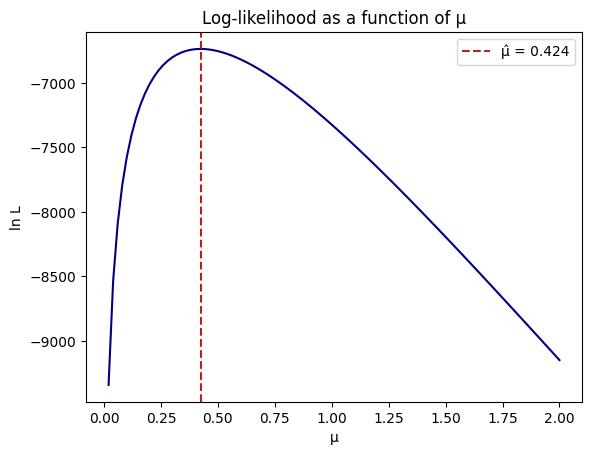

In [ ]:
# --- plot like the slide ---
plt.plot(mu_values, lnL_values, color="navy")
plt.axvline(mu_hat, color="firebrick", linestyle="--", label=f"µ̂ = {mu_hat:.3f}")
plt.xlabel("µ")
plt.ylabel("ln L")
plt.title("Log-likelihood as a function of µ")
plt.legend()
plt.show()

In [ ]:
# ======================================================================
# BRANCH SWITCH TRIAL
# ======================================================================

# new branch data (EHD3) --> "Sarcophilus_harrisii" <-> "Carlito_syrichta"
edges = [
    (117, "Monodelphis_domestica"),
    (118, "Notamacropus_eugenii"),
    (118, "Phascolarctos_cinereus"),
    (119, 118),
    (119, "Carlito_syrichta"),
    (117, 119),
    (120, 117),
    (121, "Sarcophilus_harrisii"),
    (122, "Erinaceus_europaeus"),
    (122, "Sorex_araneus"),
    (121, 122),
    (123, 121),
    (124, "Ochotona_princeps"),
    (124, "Oryctolagus_cuniculus"),
    (123, 124),
    (125, 123),
    (125, "Choloepus_hoffmanni"),
    (126, 125),
    (127, "Aotus_nancymaae"),
    (128, "Callithrix_jacchus"),
    (128, "Saimiri_boliviensis"),
    (127, 128),
    (129, 127),
    (129, "Cebus_capucinus"),
    (130, 129),
    (131, "Cercocebus_atys"),
    (131, "Mandrillus_leucophaeus"),
    (132, 131),
    (132, "Papio_anubis"),
    (133, 132),
    (134, "Macaca_fascicularis"),
    (134, "Macaca_mulatta"),
    (135, 134),
    (135, "Macaca_nemestrina"),
    (133, 135),
    (136, 133),
    (136, "Chlorocebus_sabaeus"),
    (137, 136),
    (138, "Colobus_angolensis"),
    (139, "Piliocolobus_tephrosceles"),
    (140, "Rhinopithecus_bieti"),
    (140, "Rhinopithecus_roxellana"),
    (139, 140),
    (138, 139),
    (137, 138),
    (141, 137),
    (142, "Gorilla_gorilla"),
    (142, "Homo_sapiens"),
    (143, 142),
    (144, "Pan_paniscus"),
    (144, "Pan_troglodytes"),
    (143, 144),
    (145, 143),
    (145, "Pongo_abelii"),
    (146, 145),
    (146, "Nomascus_leucogenys"),
    (141, 146),
    (130, 141),
    (147, 130),
    (147, "Galeopterus_variegatus"),
    (148, 147),
    (149, "Microcebus_murinus"),
    (149, "Propithecus_coquereli"),
    (150, 149),
    (150, "Otolemur_garnettii"),
    (148, 150),
    (151, 148),
    (152, "Castor_canadensis"),
    (152, "Dipodomys_ordii"),
    (153, 152),
    (154, "Cricetulus_griseus"),
    (154, "Mesocricetus_auratus"),
    (155, 154),
    (156, "Microtus_ochrogaster"),
    (156, "Peromyscus_maniculatus"),
    (155, 156),
    (157, 155),
    (158, "Meriones_unguiculatus"),
    (159, "Mus_caroli"),
    (160, "Mus_musculus"),
    (160, "Mus_spretus"),
    (159, 160),
    (161, 159),
    (161, "Mus_pahari"),
    (162, 161),
    (162, "Rattus_norvegicus"),
    (158, 162),
    (157, 158),
    (163, 157),
    (163, "Nannospalax_galili"),
    (164, 163),
    (164, "Jaculus_jaculus"),
    (153, 164),
    (165, 153),
    (166, "Cavia_aperea"),
    (166, "Cavia_porcellus"),
    (167, 166),
    (167, "Octodon_degus"),
    (168, 167),
    (168, "Chinchilla_lanigera"),
    (169, 168),
    (169, "Heterocephalus_glaber"),
    (170, 169),
    (170, "Fukomys_damarensis"),
    (171, 170),
    (172, "Ictidomys_tridecemlineatus"),
    (172, "Marmota_marmota_marmota"),
    (171, 172),
    (165, 171),
    (173, 165),
    (174, "Tupaia_belangeri"),
    (174, "Tupaia_chinensis"),
    (175, 174),
    (176, "Chrysochloris_asiatica"),
    (176, "Orycteropus_afer_afer"),
    (177, 176),
    (178, "Loxodonta_africana"),
    (178, "Trichechus_manatus_latirostris"),
    (179, 178),
    (179, "Procavia_capensis"),
    (177, 179),
    (180, 177),
    (180, "Elephantulus_edwardii"),
    (181, 180),
    (181, "Echinops_telfairi"),
    (182, 181),
    (182, "Dasypus_novemcinctus"),
    (183, 182),
    (184, "Manis_javanica"),
    (185, "Condylura_cristata"),
    (186, "Ceratotherium_simum_simum"),
    (187, "Equus_asinus"),
    (188, "Equus_caballus"),
    (188, "Equus_przewalskii"),
    (187, 188),
    (186, 187),
    (189, 186),
    (190, "Eptesicus_fuscus"),
    (191, "Myotis_brandtii"),
    (191, "Myotis_lucifugus"),
    (192, 191),
    (192, "Myotis_davidii"),
    (190, 192),
    (193, 190),
    (193, "Miniopterus_natalensis"),
    (194, 193),
    (195, "Hipposideros_armiger"),
    (195, "Rhinolophus_sinicus"),
    (196, 195),
    (197, "Pteropus_alecto"),
    (197, "Pteropus_vampyrus"),
    (198, 197),
    (198, "Rousettus_aegyptiacus"),
    (196, 198),
    (194, 196),
    (199, 194),
    (200, "Balaenoptera_acutorostrata_scammoni"),
    (201, "Delphinapterus_leucas"),
    (202, "Orcinus_orca"),
    (202, "Tursiops_truncatus"),
    (201, 202),
    (203, 201),
    (203, "Lipotes_vexillifer"),
    (204, 203),
    (204, "Physeter_catodon"),
    (200, 204),
    (205, 200),
    (206, "Bison_bison_bison"),
    (206, "Bos_mutus"),
    (207, 206),
    (208, "Bos_indicus"),
    (208, "Bos_taurus"),
    (207, 208),
    (209, 207),
    (209, "Bubalus_bubalis"),
    (210, 209),
    (211, "Capra_hircus"),
    (212, "Ovis_aries"),
    (212, "Pantholops_hodgsonii"),
    (211, 212),
    (213, 211),
    (213, "Odocoileus_virginianus_texanus"),
    (210, 213),
    (205, 210),
    (214, 205),
    (214, "Sus_scrofa"),
    (215, 214),
    (216, "Camelus_bactrianus"),
    (217, "Camelus_dromedarius"),
    (217, "Camelus_ferus"),
    (216, 217),
    (218, 216),
    (218, "Vicugna_pacos"),
    (215, 218),
    (219, 215),
    (220, "Ailuropoda_melanoleuca"),
    (220, "Ursus_maritimus"),
    (221, 220),
    (222, "Enhydra_lutris_kenyoni"),
    (222, "Mustela_putorius"),
    (221, 222),
    (223, 221),
    (224, "Leptonychotes_weddellii"),
    (224, "Neomonachus_schauinslandi"),
    (225, 224),
    (225, "Odobenus_rosmarus_divergens"),
    (223, 225),
    (226, 223),
    (226, "Canis_familiaris"),
    (227, 226),
    (228, "Felis_catus"),
    (229, "Panthera_pardus"),
    (229, "Panthera_tigris_altaica"),
    (228, 229),
    (230, 228),
    (230, "Acinonyx_jubatus"),
    (227, 230),
    (219, 227),
    (199, 219),
    (189, 199),
    (185, 189),
    (184, 185),
    (183, 184),
    (175, 183),
    (173, 175),
    (151, 173),
    (126, 151),
    (120, 126),
    (231, 120),
    (231, "Ornithorhynchus_anatinus")
]


In [ ]:
class Alignment:
    STATES = "ACGT"                                   # order of the 4 vector entries
    STATE_INDEX = {s: i for i, s in enumerate(STATES)}

    def __init__(self, msa_string):
        # --- your original parsing code, unchanged in logic ---
        list_msa = msa_string.split("\n")
        self.seqDict = {}
        index = 0
        while index < len(list_msa):
            elem = list_msa[index]
            if elem[0] == ">":                        # a name line
                name = elem.lstrip(">")
                seq = list_msa[index + 1]             # sequence is on the next line
                self.seqDict[name] = seq
            index += 1

        self.names = list(self.seqDict.keys())
        self.n_sites = len(self.seqDict[self.names[0]])

        # Every sequence in an alignment must have the same length.
        assert all(len(s) == self.n_sites for s in self.seqDict.values()), \
            "Sequences have different lengths, so this is not an alignment"

        # Build the one-hot vectors ONCE for all leaves and all sites.
        # leaf_vectors[name] has shape (n_sites, 4), and row i is the state
        # vector u of that leaf at site i, e.g. A -> [1, 0, 0, 0].
        self.leaf_vectors = {name: self._to_vectors(seq)
                             for name, seq in self.seqDict.items()}

    def _to_vectors(self, seq):
        U = np.zeros((len(seq), 4))
        for i, base in enumerate(seq.upper()):
            if base in self.STATE_INDEX:
                U[i, self.STATE_INDEX[base]] = 1.0
            else:
                U[i, :] = 1.0                         # gap or N: any state possible
        return U

In [ ]:
class Tree:
    def __init__(self, edges, lengths):
        assert len(edges) == len(lengths), "Need one length per edge"

        # children[parent] = list of (child, branch_length)
        self.children = {}
        # branch_length[child] = length of the branch leading INTO that child.
        # Every node except the root has exactly one parent, so this is unambiguous.
        self.branch_length = {}

        all_children = set()
        for (parent, child), t in zip(edges, lengths):
            self.children.setdefault(parent, []).append((child, t))
            self.branch_length[child] = t
            all_children.add(child)

        # The root is the only parent that is never a child.
        self.root = (set(self.children) - all_children).pop()

        # Internal nodes ordered so that children come BEFORE their parents.
        # This is the order in which pruning must be performed.
        self.postorder = self._postorder(self.root)

    def _postorder(self, node):
        if node not in self.children:                 # leaf: nothing to compute
            return []
        order = []
        for child, _ in self.children[node]:
            order += self._postorder(child)
        order.append(node)                            # node comes after its children
        return order

In [ ]:
def make_Q(mu):
    """Off-diagonal entries = mu, diagonal = -3*mu, so each row sums to 0."""
    Q = np.full((4, 4), mu)
    np.fill_diagonal(Q, -3.0 * mu)
    return Q

PI = np.full(4, 0.25)                                 # equilibrium frequencies


def log_likelihood(tree, aln, mu, return_sites=False):
    Q = make_Q(mu)

    # Transition matrix e^(Q*t) for each branch, computed ONCE per mu
    # (not once per site). P[child][i, j] = probability that the parent is in
    # state i and the child is in state j after time t.
    P = {child: expm(Q * t) for child, t in tree.branch_length.items()}

    site_logliks = np.zeros(aln.n_sites)

    # ---- loop over alignment columns (sites) ----
    for site in range(aln.n_sites):

        # v[node] is the 4-element likelihood vector at that node.
        # For leaves it is the one-hot vector u of the observed nucleotide.
        v = {leaf: aln.leaf_vectors[leaf][site] for leaf in aln.names}

        # Visit internal nodes from the tips toward the root (Felsenstein pruning).
        for node in tree.postorder:
            v_node = np.ones(4)                       # neutral element of the product
            for child, t in tree.children[node]:
                # Propagate the child's vector up its branch: e^(Q t) x v_child.
                # Entry i = P(subtree data below child | node has state i).
                propagated = P[child] @ v[child]
                # Merge siblings with the element-wise (Hadamard) product.
                v_node = v_node * propagated
            v[node] = v_node

        # At the root, weight by equilibrium frequencies: L(D_i | T) = pi . v_root
        site_lik = PI @ v[tree.root]
        site_logliks[site] = np.log(site_lik)

    total = site_logliks.sum()                        # sum of ln L over all sites
    return (total, site_logliks) if return_sites else total

In [ ]:
aln = Alignment(msa)
tree = Tree(edges, lengths)

print("Number of sequences:", len(aln.seqDict))
print("Number of sites    :", aln.n_sites)
print("Root node          :", tree.root)
print("Postorder (internal):", tree.postorder)

Number of sequences: 116
Number of sites    : 201
Root node          : 231
Postorder (internal): [118, 119, 117, 122, 121, 124, 123, 125, 128, 127, 129, 131, 132, 134, 135, 133, 136, 140, 139, 138, 137, 142, 144, 143, 145, 146, 141, 130, 147, 149, 150, 148, 152, 154, 156, 155, 160, 159, 161, 162, 158, 157, 163, 164, 153, 166, 167, 168, 169, 170, 172, 171, 165, 174, 176, 178, 179, 177, 180, 181, 182, 188, 187, 186, 191, 192, 190, 193, 195, 197, 198, 196, 194, 202, 201, 203, 204, 200, 206, 208, 207, 209, 212, 211, 213, 210, 205, 214, 217, 216, 218, 215, 220, 222, 221, 224, 225, 223, 226, 229, 228, 230, 227, 219, 199, 189, 185, 184, 183, 175, 173, 151, 126, 120, 231]


In [ ]:
# Sanity check: rows of P(t) must sum to 1 (valid probabilities).
assert np.allclose(expm(make_Q(0.3) * 0.1).sum(axis=1), 1.0)

# --- 2a: fixed mu = 0.3 ---
lnL, per_site = log_likelihood(tree, aln, mu=0.3, return_sites=True)
print(f"\nlnL at mu = 0.3: {lnL:.4f}")
print("First 5 per-site ln-likelihoods:", np.round(per_site[:5], 4))


lnL at mu = 0.3: -6982.3706
First 5 per-site ln-likelihoods: [-33.67   -36.6044 -34.2605 -41.0889 -24.5646]


In [ ]:
# --- 2b: range of mu values ---
mu_values = np.linspace(0.02, 2.0, 100)
lnL_values = [log_likelihood(tree, aln, mu) for mu in mu_values]

# Coarse estimate from the grid ...
mu_hat_grid = mu_values[np.argmax(lnL_values)]
# ... refined with a 1-D optimiser (maximise lnL = minimise -lnL).
res = minimize_scalar(lambda m: -log_likelihood(tree, aln, m),
                      bounds=(0.001, 5.0), method="bounded")
mu_hat = res.x
print(f"mu-hat (grid)     : {mu_hat_grid:.3f}")
print(f"mu-hat (optimised): {mu_hat:.4f}   lnL = {-res.fun:.4f}")


mu-hat (grid)     : 0.440
mu-hat (optimised): 0.4418   lnL = -6898.9220


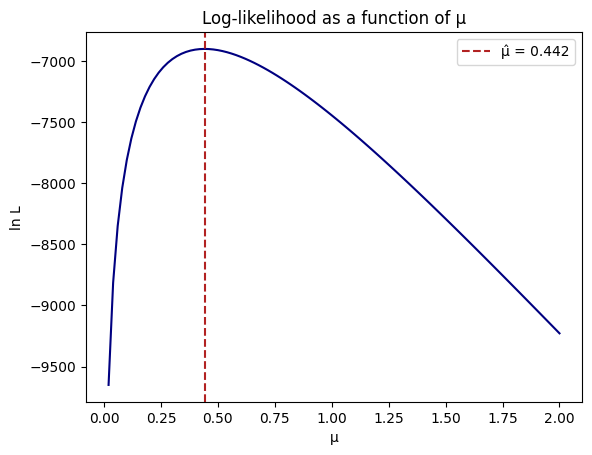

In [ ]:
# --- plot like the slide ---
plt.plot(mu_values, lnL_values, color="navy")
plt.axvline(mu_hat, color="firebrick", linestyle="--", label=f"µ̂ = {mu_hat:.3f}")
plt.xlabel("µ")
plt.ylabel("ln L")
plt.title("Log-likelihood as a function of µ")
plt.legend()
plt.show()